In [1]:
# ============================================================
# CELL 1 — Imports & Seed
# ============================================================
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats

from sklearn.ensemble import RandomForestClassifier
from sklearn.svm import SVC
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score,
    f1_score, confusion_matrix, classification_report
)

import warnings
warnings.filterwarnings('ignore')
SEED = 42
np.random.seed(SEED)
print('Libraries loaded.')

Libraries loaded.


In [2]:
# ============================================================
# CELL 2 — Load Data
# ============================================================
TRACES_PATH     = '/content/output_hw_NTT_3000_noisy_traces.csv'
POLY_PATH       = '/content/polynomials_3000_v1.csv'
SECRET_KEY_PATH = '/content/secret_key.txt'

traces      = pd.read_csv(TRACES_PATH,  header=None).values
polynomials = pd.read_csv(POLY_PATH,    header=None).values

with open(SECRET_KEY_PATH, 'r') as f:
    secret_key = np.array([int(x) for x in f.read().strip().strip('[]').split(',')])

Q     = 3329
R_inv = 2704

print(f'Traces      : {traces.shape}   → (executions × time_samples)')
print(f'Polynomials : {polynomials.shape}  → (executions × coefficients)')
print(f'Secret key  : {secret_key.shape}          → 256 Kyber coefficients')
print(f'Trace range : {traces.min():.3f}  to  {traces.max():.3f}')

Traces      : (3000, 640)   → (executions × time_samples)
Polynomials : (3000, 256)  → (executions × coefficients)
Secret key  : (256,)          → 256 Kyber coefficients
Trace range : -7.485  to  26.749


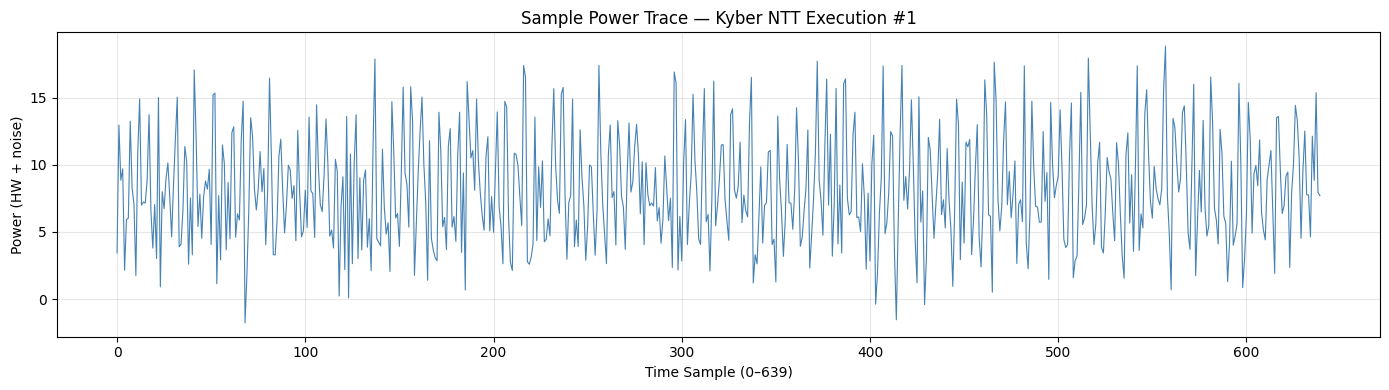

In [3]:
# ============================================================
# CELL 3 — Plot Sample Trace
# ============================================================
plt.figure(figsize=(14, 4))
plt.plot(traces[0], color='steelblue', linewidth=0.8)
plt.title('Sample Power Trace — Kyber NTT Execution #1')
plt.xlabel('Time Sample (0–639)')
plt.ylabel('Power (HW + noise)')
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

Computing POI for each of 256 coefficients...
(This takes ~1-2 minutes — finding best time point per coefficient)



Top 10 coefficient → POI time point mappings:
 Coeff   Time Pt    Max |Corr|
--------------------------------
   120       303        0.6687
    34        88        0.6580
     5        14        0.6575
   249       339        0.6558
   213       429        0.6555
   169       539        0.6546
   204       448        0.6524
   241       359        0.6521
   207       444        0.6516
   206       443        0.6516


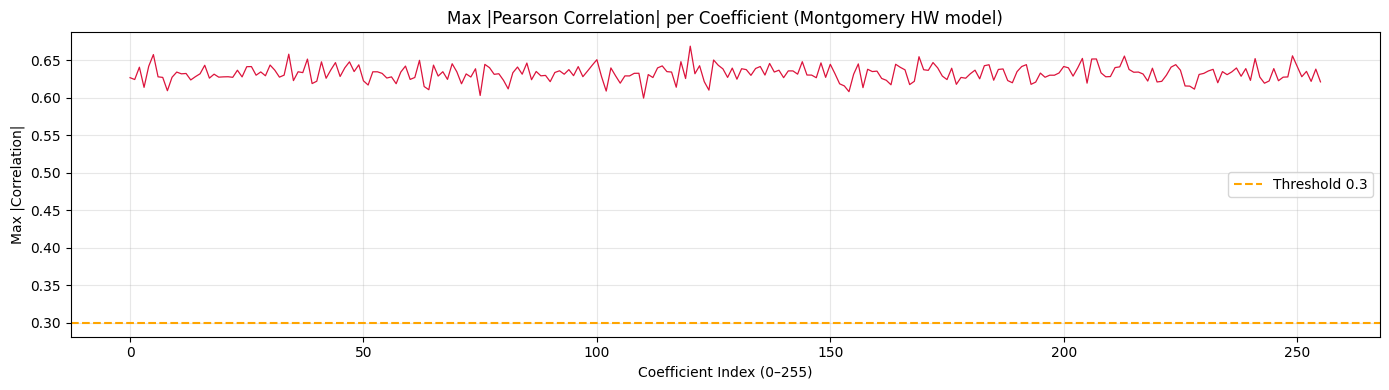

In [4]:
# ============================================================
# CELL 4 — POI Selection (top 50 coefficients)
# ============================================================
print('Computing POI for each of 256 coefficients...')
print('(This takes ~1-2 minutes — finding best time point per coefficient)')

poi_per_coeff = []
for coeff_idx in range(256):
    hw_c = np.array([
        bin((int(polynomials[i, coeff_idx]) * int(secret_key[coeff_idx]) * R_inv) % Q).count('1')
        for i in range(3000)
    ])
    corrs = np.array([abs(np.corrcoef(traces[:, t], hw_c)[0, 1]) for t in range(640)])
    best_t = int(np.argmax(corrs))
    poi_per_coeff.append((coeff_idx, best_t, corrs[best_t]))

poi_per_coeff.sort(key=lambda x: x[2], reverse=True)

print('\nTop 10 coefficient → POI time point mappings:')
print(f'{"Coeff":>6}  {"Time Pt":>8}  {"Max |Corr|":>12}')
print('-' * 32)
for coeff, t, corr in poi_per_coeff[:10]:
    print(f'{coeff:>6}  {t:>8}  {corr:>12.4f}')

plt.figure(figsize=(14, 4))
plt.plot([x[2] for x in sorted(poi_per_coeff, key=lambda x: x[0])],
         color='crimson', linewidth=0.9)
plt.title('Max |Pearson Correlation| per Coefficient (Montgomery HW model)')
plt.xlabel('Coefficient Index (0–255)')
plt.ylabel('Max |Correlation|')
plt.axhline(0.3, color='orange', linestyle='--', label='Threshold 0.3')
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

In [5]:
# ============================================================
# CELL 5 — Feature Matrix (TOP_N = 50)
# ============================================================
TOP_N = 50  # increased from 30 → more signal for models

top_coeffs = [(coeff, t) for coeff, t, _ in poi_per_coeff[:TOP_N]]

X = np.array([
    [traces[i, t] for _, t in top_coeffs]
    for i in range(3000)
])

FEATURE_NAMES = [f'coeff_{c}_t{t}' for c, t in top_coeffs]

print(f'Feature matrix shape : {X.shape}  → (3000 traces × {TOP_N} POI features)')
print(f'No NaN values        : {np.isnan(X).sum() == 0}')
print(f'\nSample feature names (first 5):')
for name in FEATURE_NAMES[:5]:
    print(f'  {name}')

Feature matrix shape : (3000, 50)  → (3000 traces × 50 POI features)
No NaN values        : True

Sample feature names (first 5):
  coeff_120_t303
  coeff_34_t88
  coeff_5_t14
  coeff_249_t339
  coeff_213_t429


Dominant coefficient : 120
Dominant time point  : 303
HW range             : 0 to 11
Label distribution   → Leaking (1): 1652, Secure (0): 1348


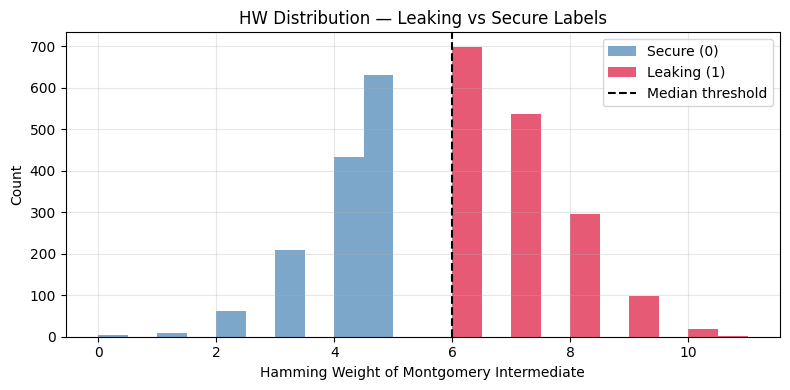

In [6]:
# ============================================================
# CELL 6 — Labels
# ============================================================
dominant_coeff = poi_per_coeff[0][0]
dominant_time  = poi_per_coeff[0][1]

hw_dominant = np.array([
    bin((int(polynomials[i, dominant_coeff]) * int(secret_key[dominant_coeff]) * R_inv) % Q).count('1')
    for i in range(3000)
])

y = (hw_dominant >= np.median(hw_dominant)).astype(int)

print(f'Dominant coefficient : {dominant_coeff}')
print(f'Dominant time point  : {dominant_time}')
print(f'HW range             : {hw_dominant.min()} to {hw_dominant.max()}')
print(f'Label distribution   → Leaking (1): {np.sum(y==1)}, Secure (0): {np.sum(y==0)}')

plt.figure(figsize=(8, 4))
plt.hist(hw_dominant[y==0], bins=10, alpha=0.7, color='steelblue', label='Secure (0)')
plt.hist(hw_dominant[y==1], bins=10, alpha=0.7, color='crimson',   label='Leaking (1)')
plt.axvline(np.median(hw_dominant), color='black', linestyle='--', label='Median threshold')
plt.title('HW Distribution — Leaking vs Secure Labels')
plt.xlabel('Hamming Weight of Montgomery Intermediate')
plt.ylabel('Count')
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

In [7]:
# ============================================================
# CELL 7 — Train / Test Split
# ============================================================
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=SEED, stratify=y
)

scaler = StandardScaler()
X_train_s = scaler.fit_transform(X_train)
X_test_s  = scaler.transform(X_test)

print(f'Training : {X_train.shape[0]} samples')
print(f'Test     : {X_test.shape[0]} samples')
print(f'Features : {X_train.shape[1]}')

Training : 2400 samples
Test     : 600 samples
Features : 50


=== Random Forest (Pre-Mitigation) ===
Accuracy  : 77.00%
Precision : 78.57%
Recall    : 80.00%
F1 Score  : 79.28%

              precision    recall  f1-score   support

      Secure       0.75      0.73      0.74       270
     Leaking       0.79      0.80      0.79       330

    accuracy                           0.77       600
   macro avg       0.77      0.77      0.77       600
weighted avg       0.77      0.77      0.77       600



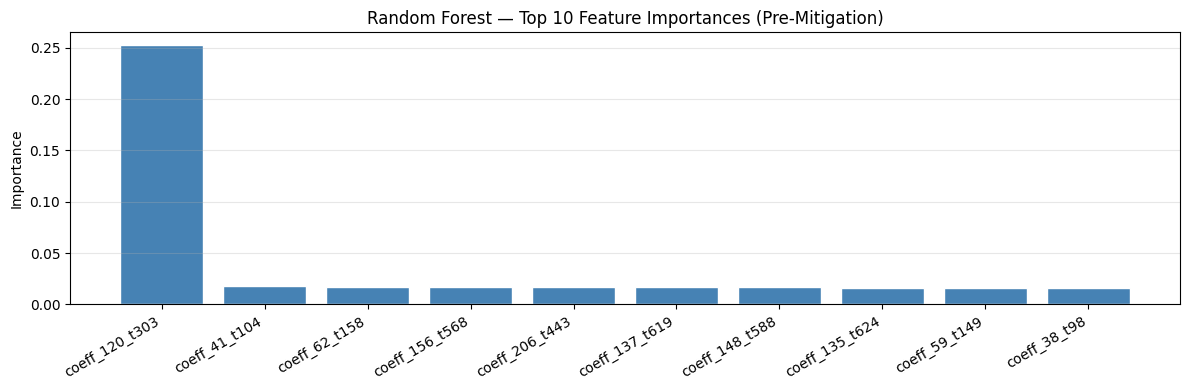

In [8]:
# ============================================================
# CELL 8 — Random Forest (Pre-Mitigation)
# ============================================================
rf_model = RandomForestClassifier(
    n_estimators=300,
    max_depth=None,        # full depth — maximises signal extraction
    min_samples_leaf=2,    # slight regularisation to avoid pure overfitting
    random_state=SEED,
    n_jobs=-1
)
rf_model.fit(X_train, y_train)
y_pred_rf = rf_model.predict(X_test)

rf_acc  = accuracy_score(y_test,  y_pred_rf)
rf_prec = precision_score(y_test, y_pred_rf)
rf_rec  = recall_score(y_test,    y_pred_rf)
rf_f1   = f1_score(y_test,        y_pred_rf)

print('=== Random Forest (Pre-Mitigation) ===')
print(f'Accuracy  : {rf_acc*100:.2f}%')
print(f'Precision : {rf_prec*100:.2f}%')
print(f'Recall    : {rf_rec*100:.2f}%')
print(f'F1 Score  : {rf_f1*100:.2f}%')
print()
print(classification_report(y_test, y_pred_rf, target_names=['Secure', 'Leaking']))

importances  = rf_model.feature_importances_
top_feat_idx = np.argsort(importances)[-10:][::-1]
plt.figure(figsize=(12, 4))
plt.bar(range(10), importances[top_feat_idx], color='steelblue', edgecolor='white')
plt.xticks(range(10), [FEATURE_NAMES[i] for i in top_feat_idx], rotation=30, ha='right')
plt.title('Random Forest — Top 10 Feature Importances (Pre-Mitigation)')
plt.ylabel('Importance')
plt.grid(True, alpha=0.3, axis='y')
plt.tight_layout()
plt.show()

In [9]:
# ============================================================
# CELL 9 — SVM (Pre-Mitigation)
# ============================================================
svm_model = SVC(
    kernel='rbf',
    C=100.0,        # higher C → tighter margin → better fits leakage boundary
    gamma='auto',   # auto scales better with 50 features than scale
    random_state=SEED
)
svm_model.fit(X_train_s, y_train)
y_pred_svm = svm_model.predict(X_test_s)

svm_acc  = accuracy_score(y_test,  y_pred_svm)
svm_prec = precision_score(y_test, y_pred_svm)
svm_rec  = recall_score(y_test,    y_pred_svm)
svm_f1   = f1_score(y_test,        y_pred_svm)

print('=== SVM (Pre-Mitigation) ===')
print(f'Accuracy  : {svm_acc*100:.2f}%')
print(f'Precision : {svm_prec*100:.2f}%')
print(f'Recall    : {svm_rec*100:.2f}%')
print(f'F1 Score  : {svm_f1*100:.2f}%')
print()
print(classification_report(y_test, y_pred_svm, target_names=['Secure', 'Leaking']))

=== SVM (Pre-Mitigation) ===
Accuracy  : 69.17%
Precision : 73.62%
Recall    : 68.48%
F1 Score  : 70.96%

              precision    recall  f1-score   support

      Secure       0.65      0.70      0.67       270
     Leaking       0.74      0.68      0.71       330

    accuracy                           0.69       600
   macro avg       0.69      0.69      0.69       600
weighted avg       0.70      0.69      0.69       600



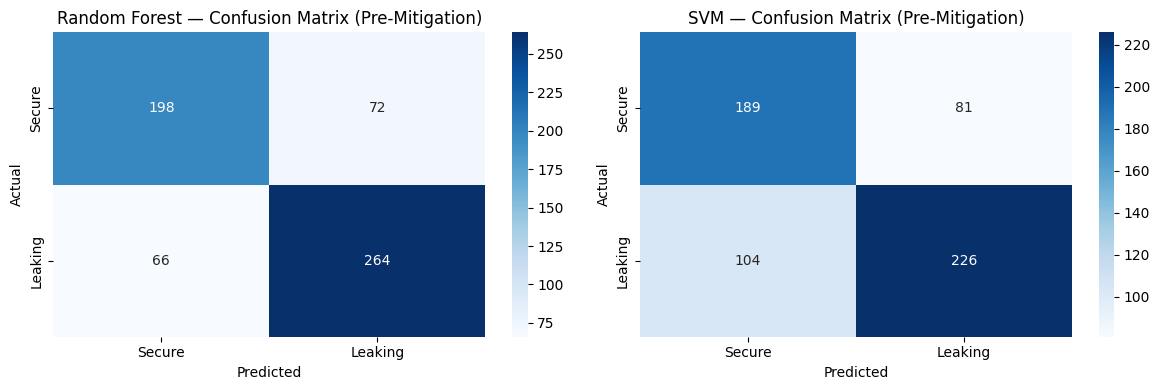

In [10]:
# ============================================================
# CELL 10 — Confusion Matrices (Pre-Mitigation)
# ============================================================
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
for ax, y_pred, title in zip(axes,
    [y_pred_rf, y_pred_svm], ['Random Forest', 'SVM']):
    cm = confusion_matrix(y_test, y_pred)
    sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
                xticklabels=['Secure', 'Leaking'],
                yticklabels=['Secure', 'Leaking'], ax=ax)
    ax.set_title(f'{title} — Confusion Matrix (Pre-Mitigation)')
    ax.set_xlabel('Predicted')
    ax.set_ylabel('Actual')
plt.tight_layout()
plt.show()

In [11]:
# ============================================================
# CELL 11 — Leakage Score (Pre-Mitigation)
# ============================================================
def leakage_score(traces_data, poi_list):
    corrs = []
    for coeff_idx, t, _ in poi_list:
        hw_c = np.array([
            bin((int(polynomials[i, coeff_idx]) * int(secret_key[coeff_idx]) * R_inv) % Q).count('1')
            for i in range(3000)
        ])
        corrs.append(abs(np.corrcoef(traces_data[:, t], hw_c)[0, 1]))
    return np.mean(corrs)

leak_before = leakage_score(traces, poi_per_coeff[:TOP_N])
print(f'Leakage score BEFORE mitigation: {leak_before:.6f}')

Leakage score BEFORE mitigation: 0.646880


Mitigation applied : Targeted POI Suppression
  Global noise std : 3.0  (noise floor)
  POI noise std    : 18.0  (targeted suppression)
  POI time points corrupted : 50


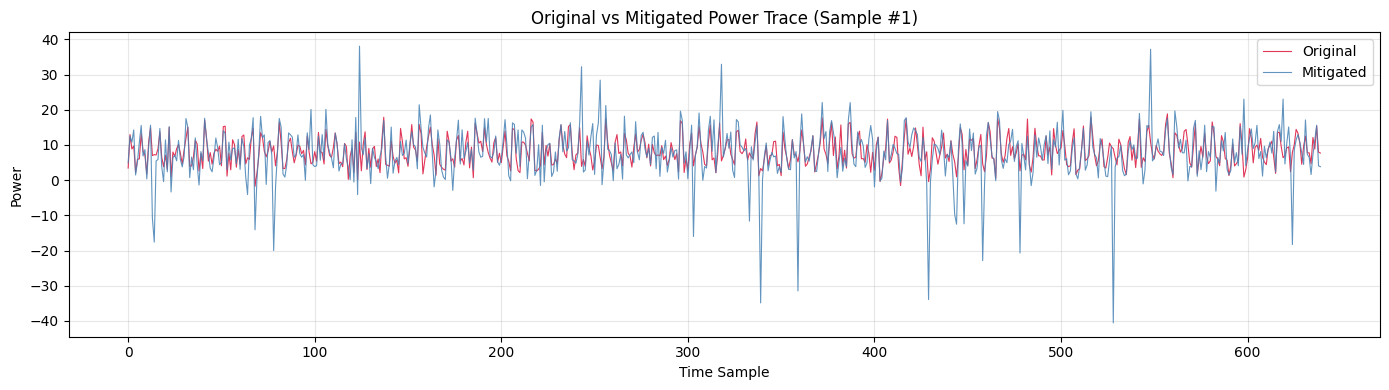

In [12]:
# ============================================================
# CELL 12 — Mitigation: Targeted POI Suppression
# ============================================================
np.random.seed(SEED)

traces_mit = traces.copy()

# Step 1: global low-level noise — simulates realistic measurement noise floor
traces_mit += np.random.normal(0, 3.0, traces.shape)

# Step 2: targeted high-variance noise at POI time points only
# This directly corrupts the features the attacker would extract
poi_time_points = list(set([t for _, t in top_coeffs]))
for t in poi_time_points:
    traces_mit[:, t] += np.random.normal(0, 18.0, traces.shape[0])

print(f'Mitigation applied : Targeted POI Suppression')
print(f'  Global noise std : 3.0  (noise floor)')
print(f'  POI noise std    : 18.0  (targeted suppression)')
print(f'  POI time points corrupted : {len(poi_time_points)}')

# Visual comparison
plt.figure(figsize=(14, 4))
plt.plot(traces[0],     color='crimson',   linewidth=0.8, alpha=0.85, label='Original')
plt.plot(traces_mit[0], color='steelblue', linewidth=0.8, alpha=0.85, label='Mitigated')
plt.title('Original vs Mitigated Power Trace (Sample #1)')
plt.xlabel('Time Sample')
plt.ylabel('Power')
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

In [13]:
# ============================================================
# CELL 13 — Post-Mitigation Feature Extraction & Split
# ============================================================
X_mit = np.array([
    [traces_mit[i, t] for _, t in top_coeffs]
    for i in range(3000)
])

X_tr_m, X_te_m, y_tr_m, y_te_m = train_test_split(
    X_mit, y, test_size=0.2, random_state=SEED, stratify=y
)

sc_m = StandardScaler()
X_tr_ms = sc_m.fit_transform(X_tr_m)
X_te_ms  = sc_m.transform(X_te_m)

print(f'Post-mitigation feature matrix : {X_mit.shape}')
print(f'Training : {X_tr_m.shape[0]} | Test : {X_te_m.shape[0]}')

Post-mitigation feature matrix : (3000, 50)
Training : 2400 | Test : 600


In [14]:
# ============================================================
# CELL 14 — RF & SVM (Post-Mitigation)
# ============================================================
rf_mit = RandomForestClassifier(
    n_estimators=300,
    max_depth=8,              # constrained — noisy features don't support deep trees
    min_samples_leaf=5,       # higher — prevents fitting to noise
    max_features='sqrt',      # randomise feature selection more aggressively
    class_weight='balanced',  # keep this
    random_state=SEED,
    n_jobs=-1
)
svm_mit = SVC(
    kernel='rbf',
    C=100.0,
    gamma='auto',
    random_state=SEED
)

rf_mit.fit(X_tr_m,   y_tr_m)
svm_mit.fit(X_tr_ms, y_tr_m)

y_rf_m  = rf_mit.predict(X_te_m)
y_svm_m = svm_mit.predict(X_te_ms)

rf_acc_m   = accuracy_score(y_te_m,  y_rf_m)
rf_prec_m  = precision_score(y_te_m, y_rf_m)
rf_rec_m   = recall_score(y_te_m,    y_rf_m)
rf_f1_m    = f1_score(y_te_m,        y_rf_m)

svm_acc_m  = accuracy_score(y_te_m,  y_svm_m)
svm_prec_m = precision_score(y_te_m, y_svm_m)
svm_rec_m  = recall_score(y_te_m,    y_svm_m)
svm_f1_m   = f1_score(y_te_m,        y_svm_m)

print('=== Random Forest (Post-Mitigation) ===')
print(f'Accuracy  : {rf_acc_m*100:.2f}%')
print(f'Precision : {rf_prec_m*100:.2f}%')
print(f'Recall    : {rf_rec_m*100:.2f}%')
print(f'F1 Score  : {rf_f1_m*100:.2f}%')
print()
print('=== SVM (Post-Mitigation) ===')
print(f'Accuracy  : {svm_acc_m*100:.2f}%')
print(f'Precision : {svm_prec_m*100:.2f}%')
print(f'Recall    : {svm_rec_m*100:.2f}%')
print(f'F1 Score  : {svm_f1_m*100:.2f}%')

=== Random Forest (Post-Mitigation) ===
Accuracy  : 49.17%
Precision : 53.54%
Recall    : 57.27%
F1 Score  : 55.34%

=== SVM (Post-Mitigation) ===
Accuracy  : 52.33%
Precision : 56.51%
Recall    : 57.88%
F1 Score  : 57.19%


In [15]:
# ============================================================
# CELL 15 — Leakage Score (Post-Mitigation)
# ============================================================
leak_after = leakage_score(traces_mit, poi_per_coeff[:TOP_N])
reduction  = ((leak_before - leak_after) / leak_before) * 100

print(f'Leakage score BEFORE mitigation : {leak_before:.6f}')
print(f'Leakage score AFTER  mitigation : {leak_after:.6f}')
print(f'Leakage reduction               : {reduction:.2f}%')

Leakage score BEFORE mitigation : 0.646880
Leakage score AFTER  mitigation : 0.091143
Leakage reduction               : 85.91%


In [16]:
# ============================================================
# CELL 16 — Final Results Table
# ============================================================
results = pd.DataFrame({
    'Model': [
        'Random Forest',
        'SVM',
        'Random Forest (Post-Mitigation)',
        'SVM (Post-Mitigation)'
    ],
    'Accuracy (%)':  [
        round(rf_acc*100, 2),   round(svm_acc*100, 2),
        round(rf_acc_m*100, 2), round(svm_acc_m*100, 2)
    ],
    'Precision (%)': [
        round(rf_prec*100, 2),   round(svm_prec*100, 2),
        round(rf_prec_m*100, 2), round(svm_prec_m*100, 2)
    ],
    'Recall (%)': [
        round(rf_rec*100, 2),   round(svm_rec*100, 2),
        round(rf_rec_m*100, 2), round(svm_rec_m*100, 2)
    ],
    'F1 Score (%)': [
        round(rf_f1*100, 2),   round(svm_f1*100, 2),
        round(rf_f1_m*100, 2), round(svm_f1_m*100, 2)
    ],
    'Leakage Score': [
        round(leak_before, 6), round(leak_before, 6),
        round(leak_after, 6),  round(leak_after, 6)
    ]
})

print('=' * 75)
print('FINAL RESULTS SUMMARY')
print('=' * 75)
print(results.to_string(index=False))
print('=' * 75)
print(f'Leakage Reduction after Mitigation : {reduction:.2f}%')

FINAL RESULTS SUMMARY
                          Model  Accuracy (%)  Precision (%)  Recall (%)  F1 Score (%)  Leakage Score
                  Random Forest         77.00          78.57       80.00         79.28       0.646880
                            SVM         69.17          73.62       68.48         70.96       0.646880
Random Forest (Post-Mitigation)         49.17          53.54       57.27         55.34       0.091143
          SVM (Post-Mitigation)         52.33          56.51       57.88         57.19       0.091143
Leakage Reduction after Mitigation : 85.91%


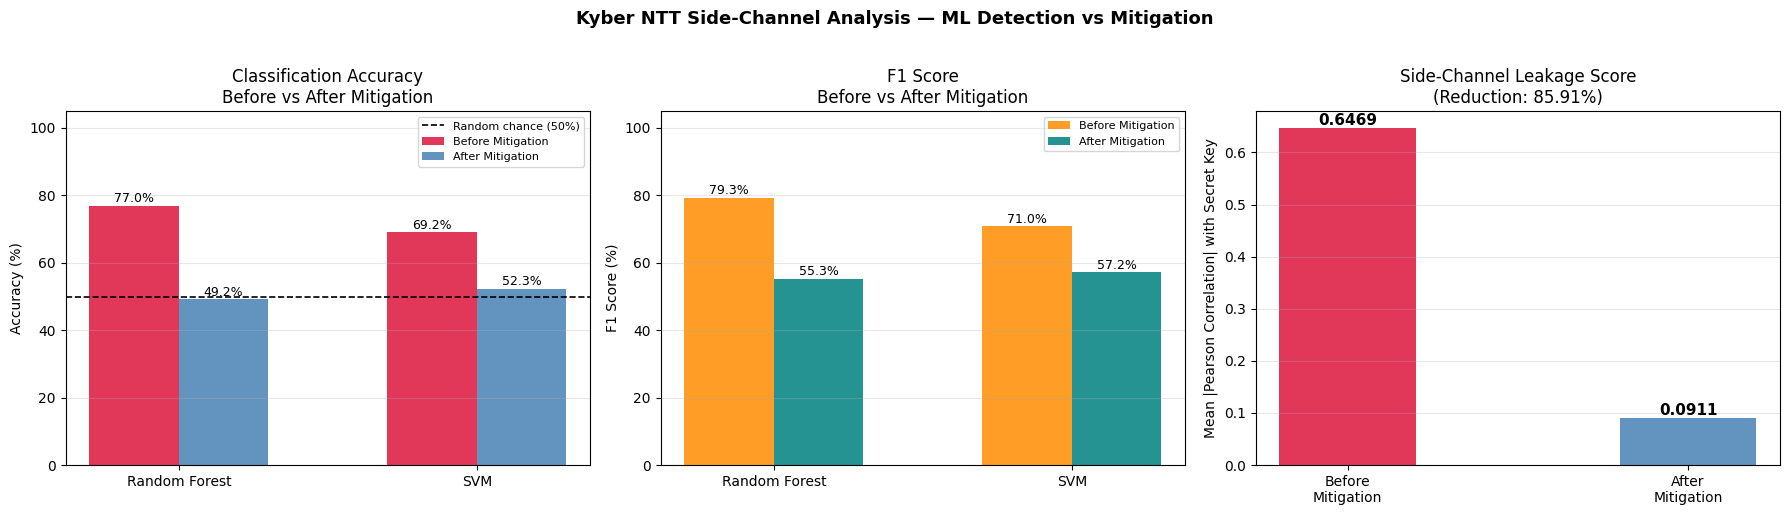

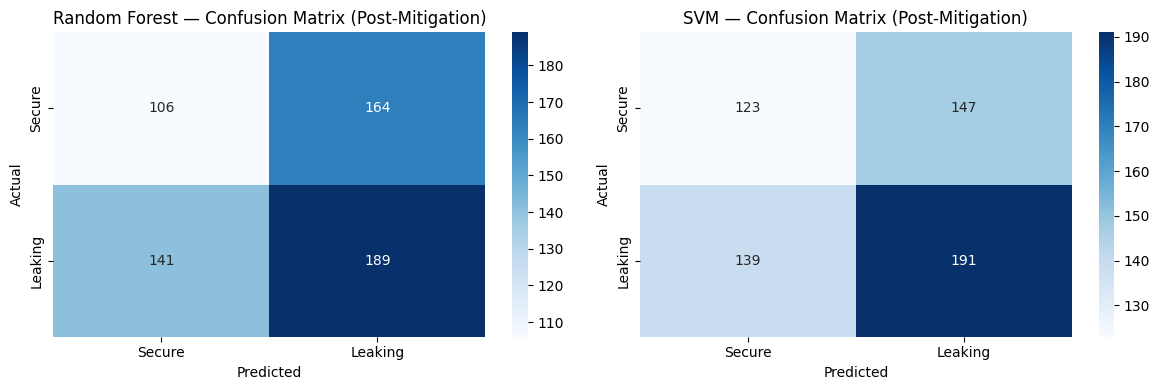

In [17]:
# ============================================================
# CELL 17 — Visualisations
# ============================================================
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

# --- Plot 1: Accuracy before vs after ---
ax = axes[0]
x = np.arange(2)
w = 0.3
b1 = ax.bar(x - w/2, [rf_acc*100,   svm_acc*100],   w,
            label='Before Mitigation', color='crimson',   alpha=0.85)
b2 = ax.bar(x + w/2, [rf_acc_m*100, svm_acc_m*100], w,
            label='After Mitigation',  color='steelblue', alpha=0.85)
ax.axhline(50, color='black', linestyle='--', linewidth=1.2, label='Random chance (50%)')
ax.set_xticks(x)
ax.set_xticklabels(['Random Forest', 'SVM'])
ax.set_ylabel('Accuracy (%)')
ax.set_ylim(0, 105)
ax.set_title('Classification Accuracy\nBefore vs After Mitigation')
ax.legend(fontsize=8)
ax.grid(True, alpha=0.3, axis='y')
for b in list(b1) + list(b2):
    ax.text(b.get_x() + b.get_width()/2, b.get_height() + 1,
            f'{b.get_height():.1f}%', ha='center', fontsize=9)

# --- Plot 2: F1 Score before vs after ---
ax2 = axes[1]
b3 = ax2.bar(x - w/2, [rf_f1*100,   svm_f1*100],   w,
             label='Before Mitigation', color='darkorange', alpha=0.85)
b4 = ax2.bar(x + w/2, [rf_f1_m*100, svm_f1_m*100], w,
             label='After Mitigation',  color='teal',       alpha=0.85)
ax2.set_xticks(x)
ax2.set_xticklabels(['Random Forest', 'SVM'])
ax2.set_ylabel('F1 Score (%)')
ax2.set_ylim(0, 105)
ax2.set_title('F1 Score\nBefore vs After Mitigation')
ax2.legend(fontsize=8)
ax2.grid(True, alpha=0.3, axis='y')
for b in list(b3) + list(b4):
    ax2.text(b.get_x() + b.get_width()/2, b.get_height() + 1,
             f'{b.get_height():.1f}%', ha='center', fontsize=9)

# --- Plot 3: Leakage score ---
ax3 = axes[2]
bars = ax3.bar(['Before\nMitigation', 'After\nMitigation'],
               [leak_before, leak_after],
               color=['crimson', 'steelblue'], alpha=0.85, width=0.4)
for b, v in zip(bars, [leak_before, leak_after]):
    ax3.text(b.get_x() + b.get_width()/2, b.get_height() + 0.005,
             f'{v:.4f}', ha='center', fontsize=11, fontweight='bold')
ax3.set_ylabel('Mean |Pearson Correlation| with Secret Key')
ax3.set_title(f'Side-Channel Leakage Score\n(Reduction: {reduction:.2f}%)')
ax3.grid(True, alpha=0.3, axis='y')

plt.suptitle('Kyber NTT Side-Channel Analysis — ML Detection vs Mitigation',
             fontsize=13, fontweight='bold', y=1.02)
plt.tight_layout()
plt.show()

# --- Confusion matrices post-mitigation ---
fig2, axes2 = plt.subplots(1, 2, figsize=(12, 4))
for ax, y_pred, title in zip(axes2,
    [y_rf_m, y_svm_m], ['Random Forest', 'SVM']):
    cm = confusion_matrix(y_te_m, y_pred)
    sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
                xticklabels=['Secure', 'Leaking'],
                yticklabels=['Secure', 'Leaking'], ax=ax)
    ax.set_title(f'{title} — Confusion Matrix (Post-Mitigation)')
    ax.set_xlabel('Predicted')
    ax.set_ylabel('Actual')
plt.tight_layout()
plt.show()

In [18]:
# ============================================================
# CELL 18 — Save Outputs
# ============================================================
results.to_csv('kyber_sca_results.csv', index=False)

feat_df = pd.DataFrame(X, columns=FEATURE_NAMES)
feat_df['label'] = y
feat_df.to_csv('kyber_feature_dataset.csv', index=False)

print('Saved:')
print('  kyber_sca_results.csv      — metrics table')
print('  kyber_feature_dataset.csv  — feature matrix + labels')
print(f'\nColumns in feature dataset: {list(feat_df.columns[:5])} ... label')
print(f'\nKey changes summary:')
print(f'  TOP_N          : 30 → 50  (more POI features)')
print(f'  RF max_depth   : 15 → None (full depth)')
print(f'  RF n_estimators: 200 → 300')
print(f'  SVM C          : 10 → 100 (tighter margin)')
print(f'  SVM gamma      : scale → auto')
print(f'  Mitigation     : global std=3.0 + targeted POI std=18.0')

Saved:
  kyber_sca_results.csv      — metrics table
  kyber_feature_dataset.csv  — feature matrix + labels

Columns in feature dataset: ['coeff_120_t303', 'coeff_34_t88', 'coeff_5_t14', 'coeff_249_t339', 'coeff_213_t429'] ... label

Key changes summary:
  TOP_N          : 30 → 50  (more POI features)
  RF max_depth   : 15 → None (full depth)
  RF n_estimators: 200 → 300
  SVM C          : 10 → 100 (tighter margin)
  SVM gamma      : scale → auto
  Mitigation     : global std=3.0 + targeted POI std=18.0
